In [ ]:

import pandas as pd

# Upload and read the recruitment dataset
from google.colab import files

uploaded = files.upload()

# Read the CSV file
file_name = list(uploaded.keys())[0]
df = pd.read_csv(file_name)

# Display first 5 rows
print(df.head())


Saving recruitment_applications.csv to recruitment_applications (1).csv
  application_id candidate_id          job_title   department  \
0        APP0001     CAND0001   Business Analyst     Business   
1        APP0002     CAND0002  Software Engineer  Engineering   
2        APP0003     CAND0003   Business Analyst     Business   
3        APP0004     CAND0004        QA Engineer      Quality   
4        APP0005     CAND0005       Data Analyst    Analytics   

  application_source application_date  experience_years  ai_screening_score  \
0  Employee Referral       2026-01-02               7.0                82.4   
1             Naukri       2026-06-19               7.0                57.1   
2             Indeed       2026-08-12               5.0                55.2   
3             Naukri       2026-06-15               2.0                74.9   
4             Campus       2026-04-26               0.0                82.8   

  application_status hire_date  time_to_hire_days  
0         

In [ ]:

# Display the number of rows and columns
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display data types
print("\nData Types:")
print(df.dtypes)

# Display dataset information
print("\nDataset Information:")
df.info()


Dataset Shape: (605, 11)

Column Names:
['application_id', 'candidate_id', 'job_title', 'department', 'application_source', 'application_date', 'experience_years', 'ai_screening_score', 'application_status', 'hire_date', 'time_to_hire_days']

Data Types:
application_id         object
candidate_id           object
job_title              object
department             object
application_source     object
application_date       object
experience_years      float64
ai_screening_score    float64
application_status     object
hire_date              object
time_to_hire_days     float64
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 605 entries, 0 to 604
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   application_id      605 non-null    object 
 1   candidate_id        605 non-null    object 
 2   job_title           605 non-null    object 
 3   department          605 

In [ ]:

# Check missing values in every column

missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values)


Missing Values:
application_id          0
candidate_id            0
job_title               0
department              0
application_source      0
application_date        0
experience_years       12
ai_screening_score      8
application_status      0
hire_date             499
time_to_hire_days     499
dtype: int64


In [ ]:

# Calculate missing-value percentages

missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

print("Missing Value Percentage:")
print(missing_percentage.round(2))


Missing Value Percentage:
application_id         0.00
candidate_id           0.00
job_title              0.00
department             0.00
application_source     0.00
application_date       0.00
experience_years       1.98
ai_screening_score     1.32
application_status     0.00
hire_date             82.48
time_to_hire_days     82.48
dtype: float64


In [ ]:

# Count duplicate application IDs

duplicate_count = df.duplicated(
    subset=['application_id']
).sum()

print("Duplicate Application Records:", duplicate_count)

# Display all duplicate records
duplicates = df[
    df.duplicated(
        subset=['application_id'],
        keep=False
    )
]

print("\nDuplicate Records:")
print(duplicates.sort_values('application_id'))


Duplicate Application Records: 5

Duplicate Records:
    application_id candidate_id         job_title department  \
132        APP0133     CAND0133       QA Engineer    Quality   
601        APP0133     CAND0133       QA Engineer    Quality   
261        APP0262     CAND0262  Business Analyst   Business   
600        APP0262     CAND0262  Business Analyst   Business   
337        APP0338     CAND0338       QA Engineer    Quality   
604        APP0338     CAND0338       QA Engineer    Quality   
454        APP0455     CAND0455      Data Analyst  Analytics   
603        APP0455     CAND0455      Data Analyst  Analytics   
575        APP0576     CAND0576   Product Manager    Product   
602        APP0576     CAND0576   Product Manager    Product   

    application_source application_date  experience_years  ai_screening_score  \
132           LinkedIn       2026-10-05               3.0                65.4   
601           LinkedIn       2026-10-05               3.0                65.4   

In [ ]:

# Count applications by status

status_counts = df['application_status'].value_counts()

print("Application Status Distribution:")
print(status_counts)


Application Status Distribution:
application_status
Rejected      256
Hired         106
Interview      77
Assessment     62
Screening      44
Applied        34
Offer          26
Name: count, dtype: int64


In [ ]:

# Create a cleaned copy of the original dataset

df_clean = df.drop_duplicates(
    subset=['application_id'],
    keep='first'
).copy()

# Check the number of records

print("Original Dataset Rows:", len(df))

print("Cleaned Dataset Rows:", len(df_clean))

# Check unique application IDs

print(
    "Unique Application IDs:",
    df_clean['application_id'].nunique()
)


Original Dataset Rows: 605
Cleaned Dataset Rows: 600
Unique Application IDs: 600


In [ ]:

# Check application status after removing duplicates

cleaned_status_counts = df_clean[
    'application_status'
].value_counts()

print("Cleaned Application Status Distribution:")
print(cleaned_status_counts)

print("\nTotal Applications:", len(df_clean))


Cleaned Application Status Distribution:
application_status
Rejected      255
Hired         105
Interview      76
Assessment     61
Screening      43
Applied        34
Offer          26
Name: count, dtype: int64

Total Applications: 600


In [ ]:

# Check missing values after duplicate removal

print("Missing Values After Cleaning:")
print(df_clean.isnull().sum())


Missing Values After Cleaning:
application_id          0
candidate_id            0
job_title               0
department              0
application_source      0
application_date        0
experience_years       12
ai_screening_score      8
application_status      0
hire_date             495
time_to_hire_days     495
dtype: int64


In [ ]:

import pandas as pd

sample = pd.Series([10, 20, None, 40])

filled = sample.fillna(0)

print(filled)


0    10.0
1    20.0
2     0.0
3    40.0
dtype: float64


In [ ]:

sample = pd.DataFrame({
    'Name': ['A', 'B', 'C'],
    'Score': [80, None, 90]
})

print(sample.dropna())


  Name  Score
0    A   80.0
2    C   90.0


In [ ]:

# Convert numeric columns

df_clean['experience_years'] = pd.to_numeric(
    df_clean['experience_years'],
    errors='coerce'
)

df_clean['ai_screening_score'] = pd.to_numeric(
    df_clean['ai_screening_score'],
    errors='coerce'
)

df_clean['time_to_hire_days'] = pd.to_numeric(
    df_clean['time_to_hire_days'],
    errors='coerce'
)

# Convert date columns

df_clean['application_date'] = pd.to_datetime(
    df_clean['application_date'],
    format='%Y-%m-%d',
    errors='coerce'
)

df_clean['hire_date'] = pd.to_datetime(
    df_clean['hire_date'],
    format='%Y-%m-%d',
    errors='coerce'
)

print("Data Types After Conversion:")
print(df_clean.dtypes)


Data Types After Conversion:
application_id                object
candidate_id                  object
job_title                     object
department                    object
application_source            object
application_date      datetime64[ns]
experience_years             float64
ai_screening_score           float64
application_status            object
hire_date             datetime64[ns]
time_to_hire_days            float64
dtype: object


In [ ]:

# Inspect the cleaned dataset

print("Dataset Information:")
df_clean.info()

print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nFirst 5 Records:")
print(df_clean.head())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 600 entries, 0 to 599
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   application_id      600 non-null    object        
 1   candidate_id        600 non-null    object        
 2   job_title           600 non-null    object        
 3   department          600 non-null    object        
 4   application_source  600 non-null    object        
 5   application_date    600 non-null    datetime64[ns]
 6   experience_years    588 non-null    float64       
 7   ai_screening_score  592 non-null    float64       
 8   application_status  600 non-null    object        
 9   hire_date           105 non-null    datetime64[ns]
 10  time_to_hire_days   105 non-null    float64       
dtypes: datetime64[ns](2), float64(3), object(6)
memory usage: 56.2+ KB

Missing Values:
application_id          0
candidate_id            0
job_title 

In [ ]:

# Descriptive statistics for numerical columns

numeric_analysis = df_clean[
    [
        'experience_years',
        'ai_screening_score',
        'time_to_hire_days'
    ]
]

print("Descriptive Statistics:")
print(numeric_analysis.describe().round(2))

Descriptive Statistics:
       experience_years  ai_screening_score  time_to_hire_days
count            588.00              592.00             105.00
mean               4.75               65.71              43.65
std                3.06               14.85              17.56
min                0.00               22.30              14.00
25%                2.00               55.98              27.00
50%                5.00               66.55              45.00
75%                7.00               76.20              60.00
max               10.00               99.00              73.00


In [ ]:
job_analysis = df_clean['job_title'].value_counts().reset_index()

job_analysis.columns = ['Job Title', 'Applications']

job_analysis['Percentage'] = (
    job_analysis['Applications'] / len(df_clean) * 100
).round(2)

print("Applications by Job Title:")
print(job_analysis)

Applications by Job Title:
           Job Title  Applications  Percentage
0       Data Analyst           140       23.33
1  Software Engineer           134       22.33
2   Business Analyst           101       16.83
3        QA Engineer           100       16.67
4    Product Manager            70       11.67
5       HR Executive            55        9.17


In [ ]:
source_analysis = df_clean['application_source'].value_counts().reset_index()

source_analysis.columns = ['Recruitment Source', 'Applications']

source_analysis['Percentage'] = (
    source_analysis['Applications'] / len(df_clean) * 100
).round(2)

print("Applications by Recruitment Source:")
print(source_analysis)

Applications by Recruitment Source:
  Recruitment Source  Applications  Percentage
0           LinkedIn           170       28.33
1             Naukri           109       18.17
2  Employee Referral            98       16.33
3    Company Website            97       16.17
4             Indeed            76       12.67
5             Campus            50        8.33


In [ ]:
source_hiring = df_clean.groupby('application_source').agg(
    Total_Applications=('application_id', 'count'),
    Total_Hires=('application_status', lambda x: (x == 'Hired').sum())
).reset_index()

source_hiring['Hiring_Rate'] = (
    source_hiring['Total_Hires'] /
    source_hiring['Total_Applications'] * 100
).round(2)

source_hiring = source_hiring.sort_values(
    by='Hiring_Rate',
    ascending=False
)

print("Hiring Performance by Recruitment Source:")
print(source_hiring)

Hiring Performance by Recruitment Source:
  application_source  Total_Applications  Total_Hires  Hiring_Rate
1    Company Website                  97           20        20.62
2  Employee Referral                  98           20        20.41
4           LinkedIn                 170           31        18.24
0             Campus                  50            9        18.00
3             Indeed                  76           12        15.79
5             Naukri                 109           13        11.93


In [ ]:
job_hiring = df_clean.groupby('job_title').agg(
    Total_Applications=('application_id', 'count'),
    Total_Hires=('application_status', lambda x: (x == 'Hired').sum())
).reset_index()

job_hiring['Hiring_Rate'] = (
    job_hiring['Total_Hires'] /
    job_hiring['Total_Applications'] * 100
).round(2)

job_hiring = job_hiring.sort_values(
    by='Hiring_Rate',
    ascending=False
)

print("Hiring Performance by Job Title:")
print(job_hiring)

Hiring Performance by Job Title:
           job_title  Total_Applications  Total_Hires  Hiring_Rate
5  Software Engineer                 134           27        20.15
4        QA Engineer                 100           18        18.00
0   Business Analyst                 101           18        17.82
1       Data Analyst                 140           24        17.14
2       HR Executive                  55            9        16.36
3    Product Manager                  70            9        12.86


In [ ]:
department_hiring = df_clean.groupby('department').agg(
    Total_Applications=('application_id', 'count'),
    Total_Hires=('application_status', lambda x: (x == 'Hired').sum())
).reset_index()

department_hiring['Hiring_Rate'] = (
    department_hiring['Total_Hires'] /
    department_hiring['Total_Applications'] * 100
).round(2)

department_hiring = department_hiring.sort_values(
    by='Hiring_Rate',
    ascending=False
)

print("Hiring Performance by Department:")
print(department_hiring)

Hiring Performance by Department:
        department  Total_Applications  Total_Hires  Hiring_Rate
2      Engineering                 134           27        20.15
5          Quality                 100           18        18.00
1         Business                 101           18        17.82
0        Analytics                 140           24        17.14
3  Human Resources                  55            9        16.36
4          Product                  70            9        12.86


In [ ]:
status_analysis = df_clean['application_status'].value_counts().reset_index()

status_analysis.columns = ['Application Status', 'Candidates']

status_analysis['Percentage'] = (
    status_analysis['Candidates'] / len(df_clean) * 100
).round(2)

print("Application Status Distribution:")
print(status_analysis)

Application Status Distribution:
  Application Status  Candidates  Percentage
0           Rejected         255       42.50
1              Hired         105       17.50
2          Interview          76       12.67
3         Assessment          61       10.17
4          Screening          43        7.17
5            Applied          34        5.67
6              Offer          26        4.33


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

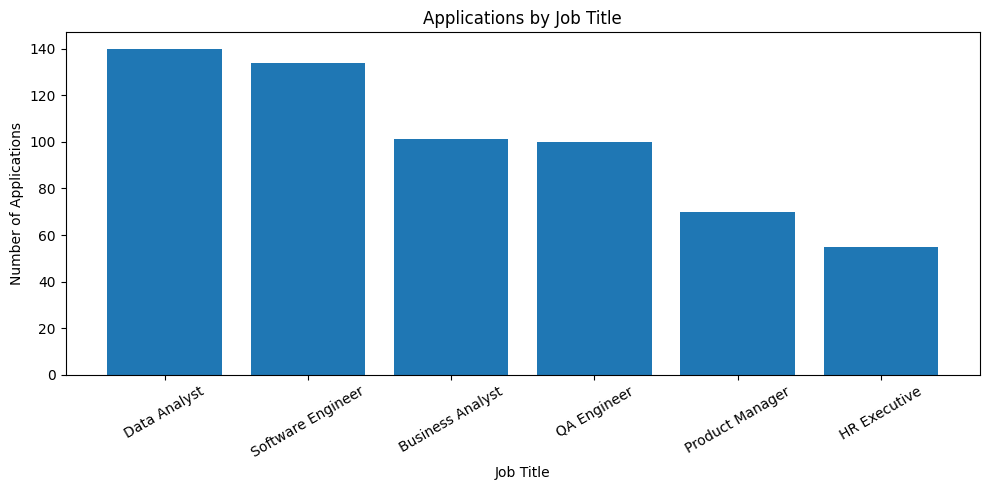

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    job_analysis['Job Title'],
    job_analysis['Applications']
)

plt.title('Applications by Job Title')
plt.xlabel('Job Title')
plt.ylabel('Number of Applications')

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

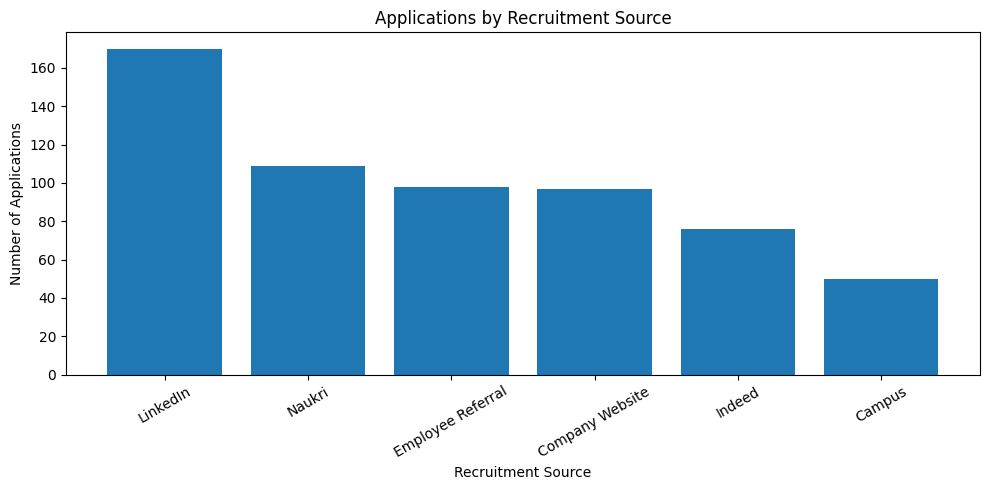

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    source_analysis['Recruitment Source'],
    source_analysis['Applications']
)

plt.title('Applications by Recruitment Source')
plt.xlabel('Recruitment Source')
plt.ylabel('Number of Applications')

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

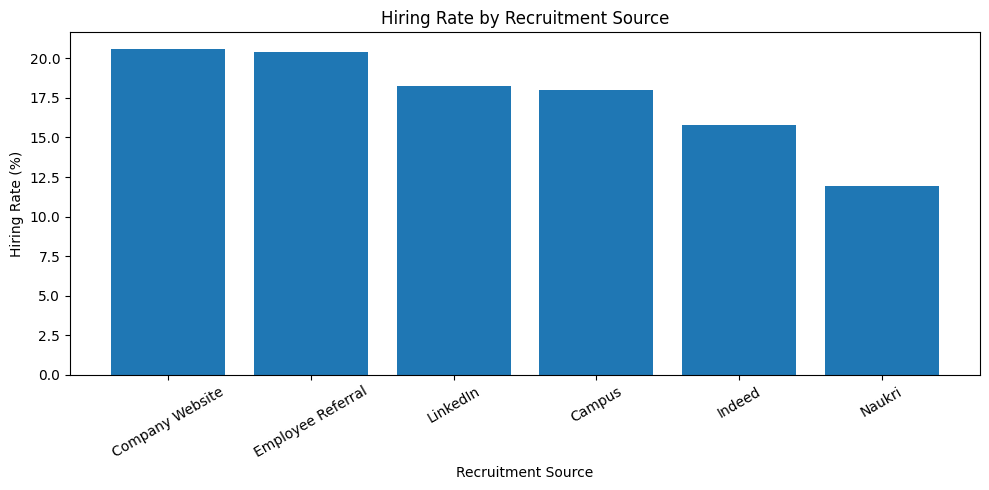

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    source_hiring['application_source'],
    source_hiring['Hiring_Rate']
)

plt.title('Hiring Rate by Recruitment Source')
plt.xlabel('Recruitment Source')
plt.ylabel('Hiring Rate (%)')

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

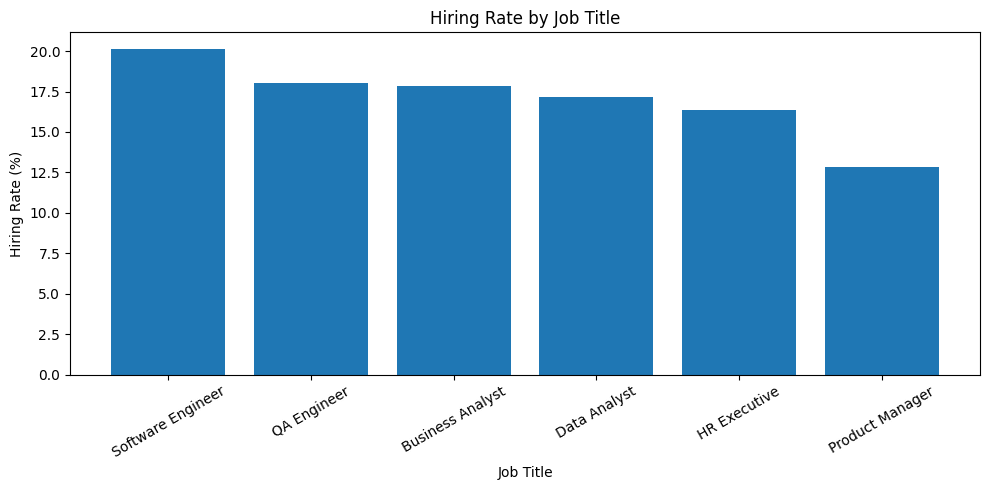

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    job_hiring['job_title'],
    job_hiring['Hiring_Rate']
)

plt.title('Hiring Rate by Job Title')
plt.xlabel('Job Title')
plt.ylabel('Hiring Rate (%)')

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

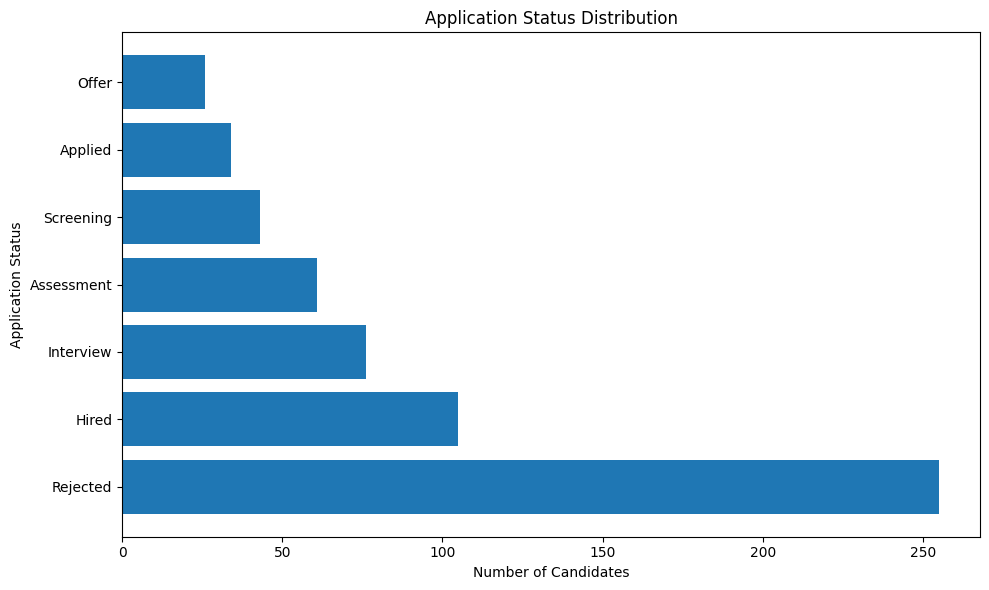

In [ ]:
plt.figure(figsize=(10, 6))

plt.barh(
    status_analysis['Application Status'],
    status_analysis['Candidates']
)

plt.title('Application Status Distribution')
plt.xlabel('Number of Candidates')
plt.ylabel('Application Status')

plt.tight_layout()
plt.show()

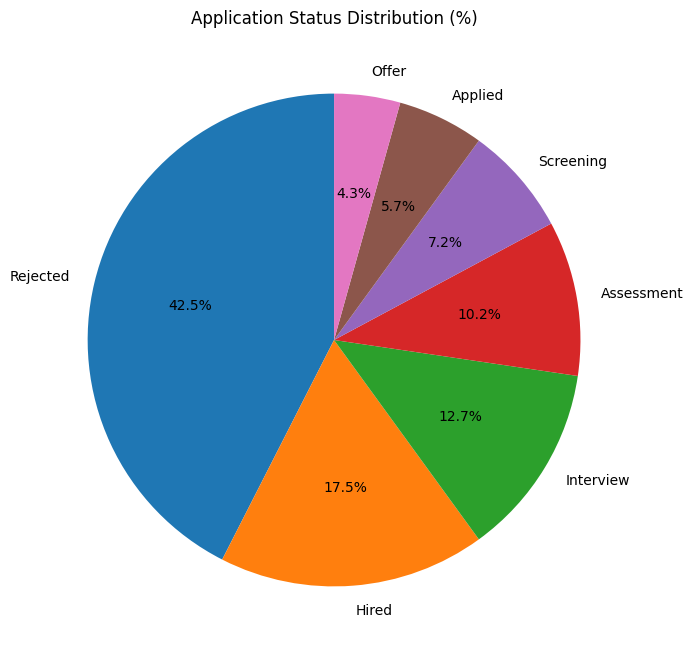

In [ ]:
plt.figure(figsize=(8, 8))

plt.pie(
    status_analysis['Candidates'],
    labels=status_analysis['Application Status'],
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Application Status Distribution (%)')

plt.show()

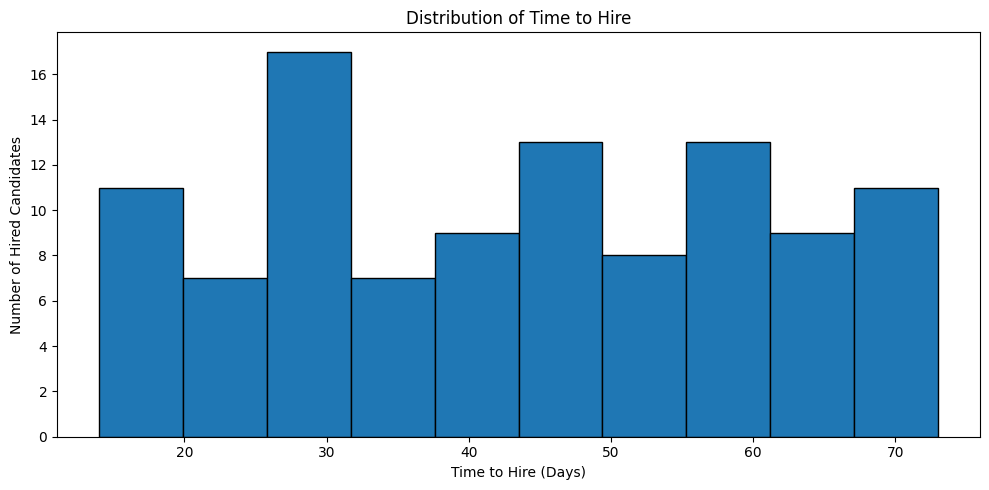

In [ ]:
plt.figure(figsize=(10, 5))

plt.hist(
    df_clean['time_to_hire_days'].dropna(),
    bins=10,
    edgecolor='black'
)

plt.title('Distribution of Time to Hire')
plt.xlabel('Time to Hire (Days)')
plt.ylabel('Number of Hired Candidates')

plt.tight_layout()
plt.show()

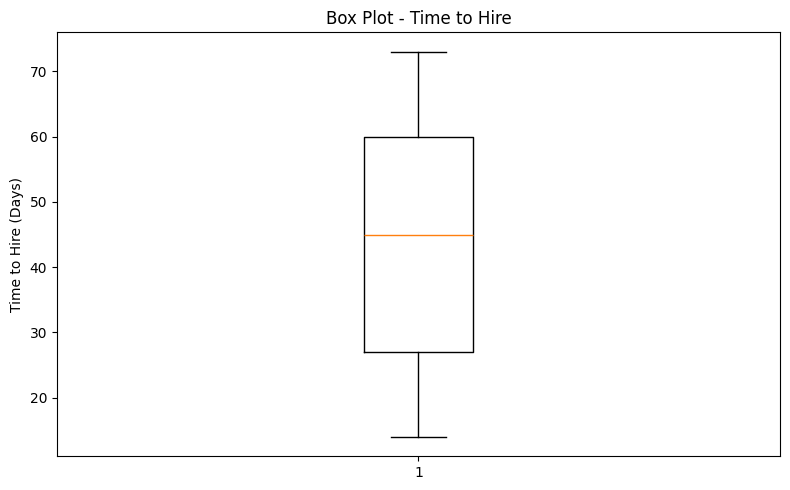

In [ ]:
plt.figure(figsize=(8, 5))

plt.boxplot(
    df_clean['time_to_hire_days'].dropna()
)

plt.title('Box Plot - Time to Hire')
plt.ylabel('Time to Hire (Days)')

plt.tight_layout()
plt.show()

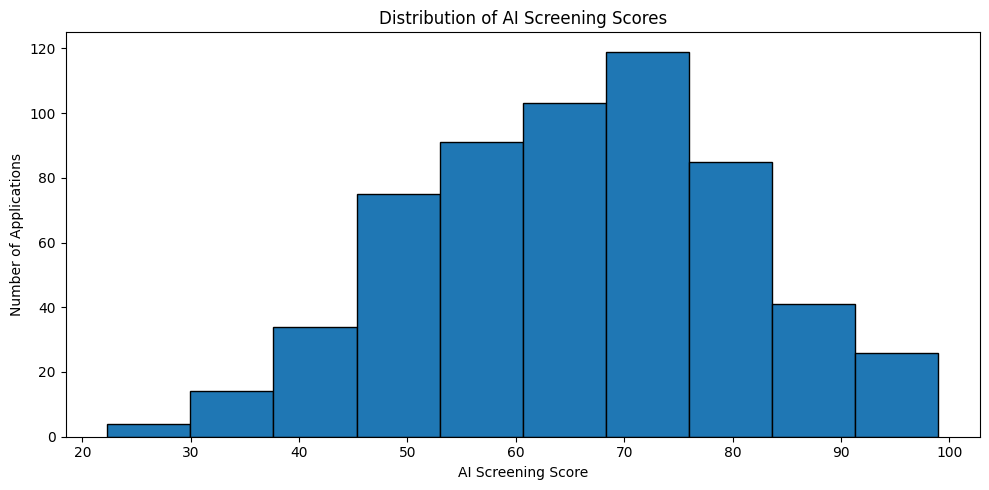

In [ ]:
plt.figure(figsize=(10, 5))

plt.hist(
    df_clean['ai_screening_score'].dropna(),
    bins=10,
    edgecolor='black'
)

plt.title('Distribution of AI Screening Scores')
plt.xlabel('AI Screening Score')
plt.ylabel('Number of Applications')

plt.tight_layout()
plt.show()

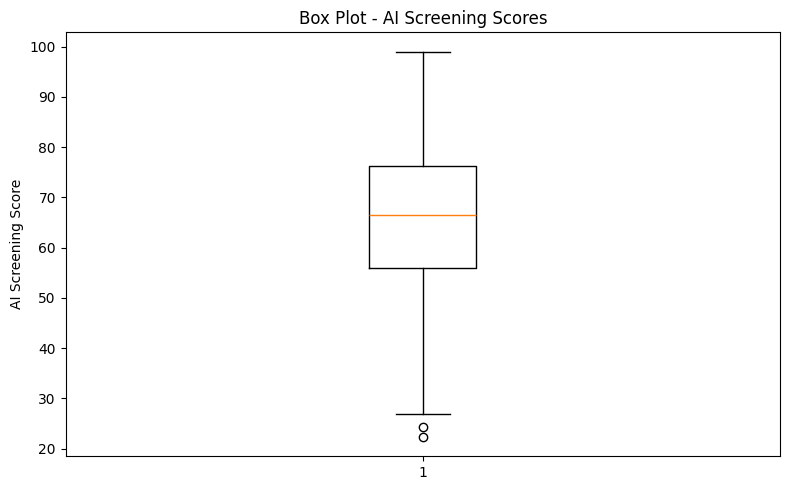

In [ ]:
plt.figure(figsize=(8, 5))

plt.boxplot(
    df_clean['ai_screening_score'].dropna()
)

plt.title('Box Plot - AI Screening Scores')
plt.ylabel('AI Screening Score')

plt.tight_layout()
plt.show()

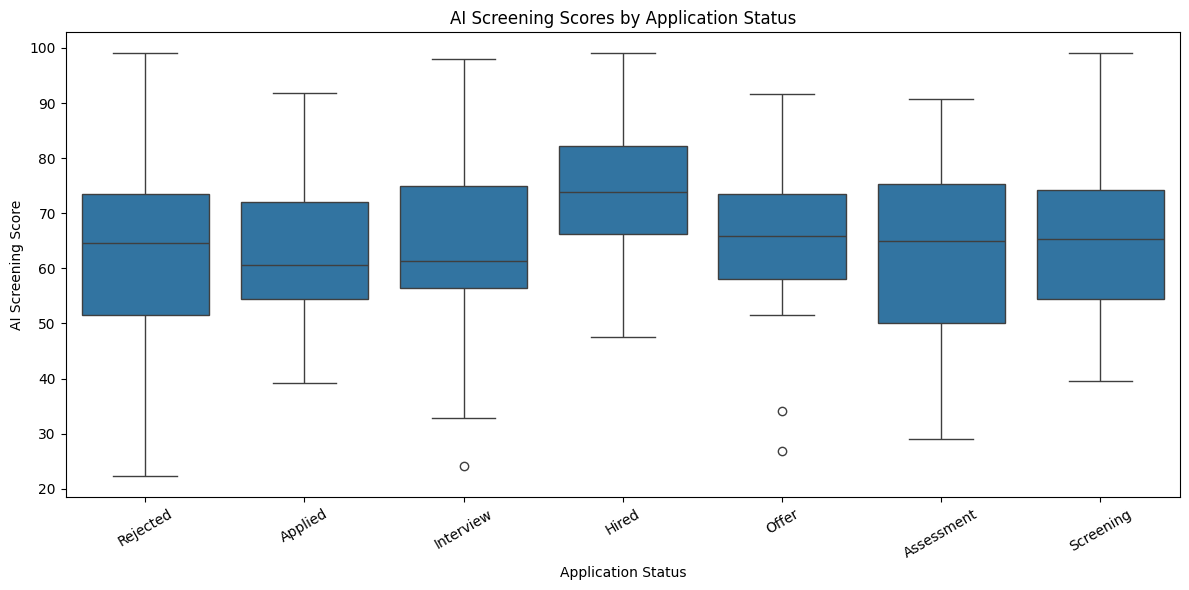

In [ ]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_clean,
    x='application_status',
    y='ai_screening_score'
)

plt.title('AI Screening Scores by Application Status')
plt.xlabel('Application Status')
plt.ylabel('AI Screening Score')

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [ ]:
status_score_analysis = df_clean.groupby(
    'application_status'
)['ai_screening_score'].mean().reset_index()

status_score_analysis.columns = [
    'Application Status',
    'Average AI Score'
]

status_score_analysis['Average AI Score'] = (
    status_score_analysis['Average AI Score'].round(2)
)

status_score_analysis = status_score_analysis.sort_values(
    by='Average AI Score',
    ascending=False
)

print("Average AI Screening Score by Status:")
print(status_score_analysis)

Average AI Screening Score by Status:
  Application Status  Average AI Score
2              Hired             74.45
6          Screening             65.55
4              Offer             64.98
3          Interview             63.92
5           Rejected             63.79
0            Applied             63.08
1         Assessment             62.77


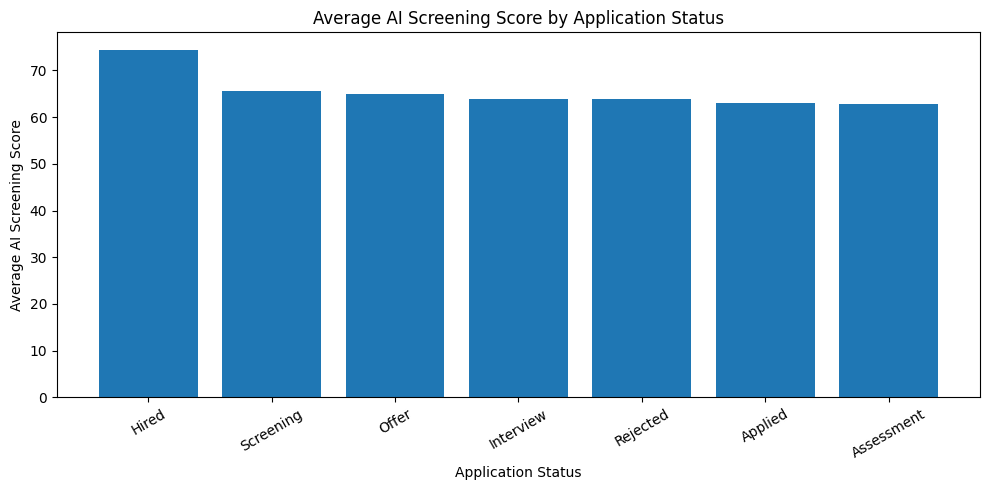

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    status_score_analysis['Application Status'],
    status_score_analysis['Average AI Score']
)

plt.title('Average AI Screening Score by Application Status')
plt.xlabel('Application Status')
plt.ylabel('Average AI Screening Score')

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [ ]:
correlation_data = df_clean[
    [
        'experience_years',
        'ai_screening_score',
        'time_to_hire_days'
    ]
]

correlation_matrix = correlation_data.corr()

print("Correlation Matrix:")
print(correlation_matrix.round(2))

Correlation Matrix:
                    experience_years  ai_screening_score  time_to_hire_days
experience_years                1.00                0.07               0.04
ai_screening_score              0.07                1.00              -0.14
time_to_hire_days               0.04               -0.14               1.00


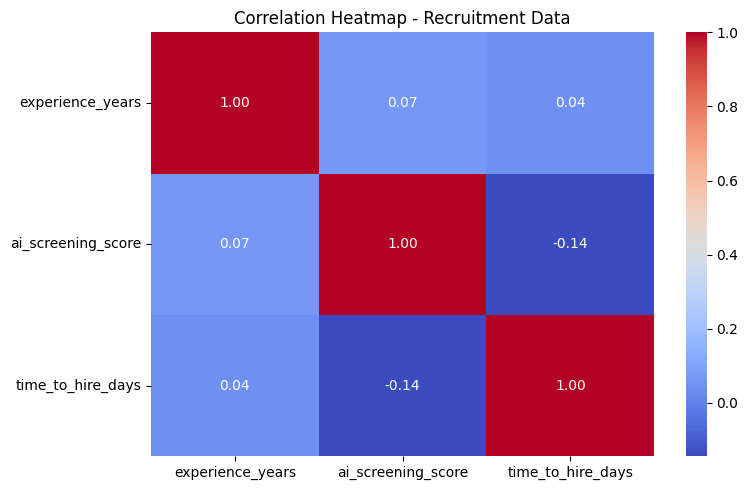

In [ ]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap - Recruitment Data')

plt.tight_layout()
plt.show()

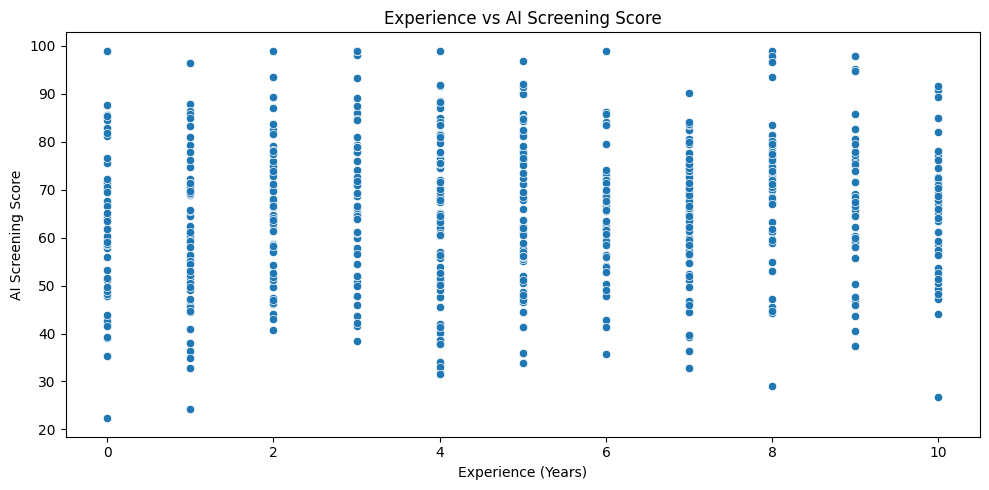

In [ ]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df_clean,
    x='experience_years',
    y='ai_screening_score'
)

plt.title('Experience vs AI Screening Score')
plt.xlabel('Experience (Years)')
plt.ylabel('AI Screening Score')

plt.tight_layout()
plt.show()

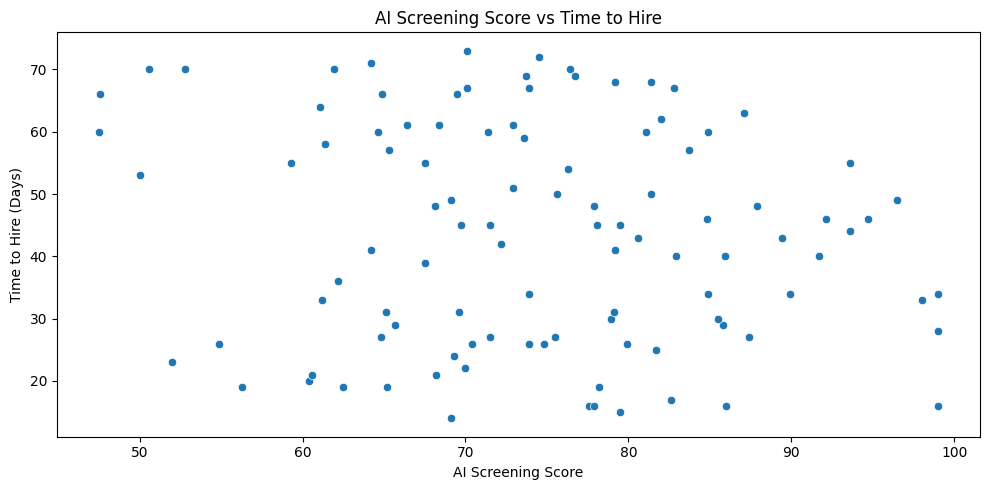

In [ ]:
plt.figure(figsize=(10, 5))

hired_data = df_clean.dropna(
    subset=['ai_screening_score', 'time_to_hire_days']
)

sns.scatterplot(
    data=hired_data,
    x='ai_screening_score',
    y='time_to_hire_days'
)

plt.title('AI Screening Score vs Time to Hire')
plt.xlabel('AI Screening Score')
plt.ylabel('Time to Hire (Days)')

plt.tight_layout()
plt.show()

In [ ]:
from google.colab import files

# Export cleaned dataset
df_clean.to_csv(
    'recruitment_applications_cleaned.csv',
    index=False
)

# Download the CSV
files.download('recruitment_applications_cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("Final Dataset Shape:", df_clean.shape)

print("\nDuplicate Application IDs:",
      df_clean['application_id'].duplicated().sum())

print("\nMissing Values:")
print(df_clean.isnull().sum())

Final Dataset Shape: (600, 11)

Duplicate Application IDs: 0

Missing Values:
application_id          0
candidate_id            0
job_title               0
department              0
application_source      0
application_date        0
experience_years       12
ai_screening_score      8
application_status      0
hire_date             495
time_to_hire_days     495
dtype: int64
